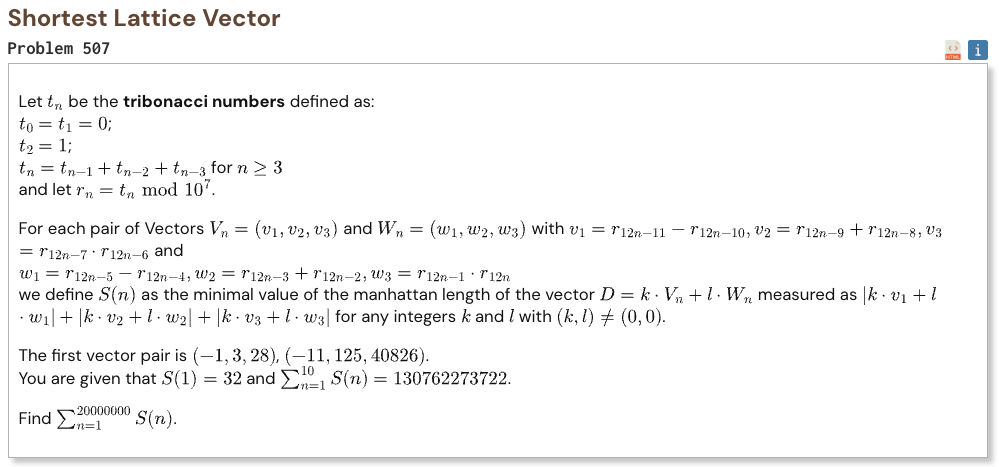

## Initial approach

- generate the tribonacci values continuously and use each group of twelve values to build the two vectors
- the two vectors generate a two dimensional lattice inside three dimensional space
- repeatedly shorten the longer vector by subtracting an integer multiple of the shorter one
- only a few candidate multiples need to be checked because the Manhattan length changes linearly between coordinate breakpoints
- continue the reduction until neither vector can be shortened
- the shorter remaining vector gives the required minimum Manhattan length
- repeat this for all twenty million vector pairs and add the results

In [1]:
%%time

MOD = 10_000_000
N = 20_000_000

def norm(v):
    return abs(v[0]) + abs(v[1]) + abs(v[2])

def best_reduction(a, b):
    best_q = 0
    best_value = norm(b)

    for i in range(3):
        if a[i] == 0:
            continue

        q = b[i] // a[i]

        for candidate in (q, q + 1):
            c = (
                b[0] - candidate * a[0],
                b[1] - candidate * a[1],
                b[2] - candidate * a[2]
            )

            value = norm(c)

            if value < best_value:
                best_value = value
                best_q = candidate

    return best_q, best_value

def shortest(v, w):
    a = v
    b = w

    while True:
        if norm(b) < norm(a):
            a, b = b, a

        old_value = norm(b)
        q, new_value = best_reduction(a, b)

        if new_value >= old_value:
            break

        b = (
            b[0] - q * a[0],
            b[1] - q * a[1],
            b[2] - q * a[2]
        )

    return min(norm(a), norm(b))

t0 = 1
t1 = 0
t2 = 0

result = 0

for _ in range(N):
    r = []

    for _ in range(12):
        r.append(t2)

        t3 = (t0 + t1 + t2) % MOD
        t0, t1, t2 = t1, t2, t3

    v = (
        r[0] - r[1],
        r[2] + r[3],
        r[4] * r[5]
    )

    w = (
        r[6] - r[7],
        r[8] + r[9],
        r[10] * r[11]
    )

    result += shortest(v, w)

print("Result:", result)

Result: 316558047002627270
CPU times: user 5min 44s, sys: 874 ms, total: 5min 45s
Wall time: 5min 46s
